# Assignment 10: Linear and Logistic Regression

**Dataset:** Ames Housing (De Cock, 2011), 2,930 homes sold in Ames, Iowa, 2006 to 2010:
https://jse.amstat.org/v19n3/decock/AmesHousing.txt

In [1]:
"""Assignment 10: preprocess the Ames Housing data, then fit linear and logistic regression."""
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter
from sklearn.base import BaseEstimator
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             precision_score, r2_score, recall_score, root_mean_squared_error)
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_FILE = Path("AmesHousing.txt")
PRICE, LOG_PRICE = "saleprice", "log_sale_price"

# A neighborhood with no homes in one training fold is encoded as the dropped first category
# when it shows up in that fold's test slice. scikit-learn warns each time; that is expected here.
warnings.filterwarnings("ignore", message="Found unknown categories", category=UserWarning)

## Question 1: Preprocessing and feature selection

In [2]:
# ---- preprocessing decisions ----
# Columns where the documentation uses "NA" to mean the home has none (no alley, no pool...).
NONE_COLUMNS = ["alley", "bsmt_qual", "bsmt_cond", "bsmt_exposure", "bsmtfin_type_1",
                "bsmtfin_type_2", "fireplace_qu", "garage_type", "garage_finish", "garage_qual",
                "garage_cond", "pool_qc", "fence", "misc_feature"]
# Quality scales, excellent to poor, which have an order and so become numbers.
QUALITY_COLUMNS = ["exter_qual", "exter_cond", "bsmt_qual", "bsmt_cond", "heating_qc",
                   "kitchen_qual", "fireplace_qu", "garage_qual", "garage_cond", "pool_qc"]
QUALITY_SCALE = {"ex": 5, "gd": 4, "ta": 3, "fa": 2, "po": 1, "none": 0}
NOMINAL_NUMBER_COLUMNS = ["ms_subclass"]   # numbers that are category codes, so they stay text
ID_COLUMNS = ["order", "pid"]              # identifiers, not features
YEAR_COLUMNS = ["year_built", "year_remod_add", "garage_yr_blt"]
SIZE_LIMIT_SQFT = 4000                     # the dataset author's recommended cut

In [3]:
def load_raw(data_file: Path) -> pd.DataFrame:
    """Read every value as text, so only an empty cell becomes null.

    pandas' default reading would also turn "NA" and "None" into nulls, but in this file those
    are real values ("the home has none", and a masonry type).

    Args:
        data_file: Path to AmesHousing.txt.

    Returns:
        The table exactly as stored, all text.
    """
    return pd.read_csv(data_file, sep="\t", dtype=str, keep_default_na=False, na_values=[""])


def clean_text(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Rename columns to snake_case, then trim and lowercase every text value.

    Args:
        frame: The raw table.

    Returns:
        The cleaned table, and a note on how many values changed.
    """
    renamed = frame.rename(columns=lambda name: name.strip().lower().replace(" ", "_")
                           .replace("/", "_"))
    cleaned = renamed.apply(lambda column: column.str.strip().str.lower())
    changed = int((cleaned != renamed).sum().sum())
    return cleaned, f"columns to snake_case; {changed:,} values trimmed or lowercased"


def mark_none(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Turn the documented code "na" into the category "none".

    Args:
        frame: The lowercase table.

    Returns:
        The table, and a note on how many values changed.
    """
    marked = frame.copy()
    marked[NONE_COLUMNS] = marked[NONE_COLUMNS].replace("na", "none")
    return marked, f"{int((marked != frame).sum().sum()):,} values of 'na' became 'none'"


def convert_types(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Turn every column whose values are all numbers into numbers, and drop the identifiers.

    Args:
        frame: The table, still all text.

    Returns:
        The table with real numbers, and a note on how many columns converted.
    """
    converted = frame.drop(columns=ID_COLUMNS)
    count = 0
    for column in converted.columns.difference(NOMINAL_NUMBER_COLUMNS):
        values = pd.to_numeric(converted[column], errors="coerce")
        if values.notna().sum() == converted[column].notna().sum():
            converted[column] = values
            count += 1
    return converted, f"{count} columns to numbers; order and pid dropped"


def remove_outliers(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Null impossible years, then remove the homes over 4,000 sq ft.

    A year after the data ends (2010) or a remodel before the build is stored wrong. The
    dataset's author recommends removing the 5 homes over 4,000 sq ft (3 aren't market sales).

    Args:
        frame: The table with numbers.

    Returns:
        The table, and a note on what changed.
    """
    fixed = frame.copy()
    wrong = 0
    for column in YEAR_COLUMNS:
        bad = fixed[column] > fixed["yr_sold"].max()
        if column == "year_remod_add":
            bad |= fixed[column] < fixed["year_built"]
        wrong += int(bad.sum())
        fixed.loc[bad, column] = np.nan
    large = fixed["gr_liv_area"] > SIZE_LIMIT_SQFT
    note = f"{wrong} impossible years nulled; {int(large.sum())} homes removed"
    return fixed[~large].copy(), note


def encode_quality(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Turn each quality scale (excellent to poor) into 5 to 1, with 0 for none.

    Args:
        frame: The table.

    Returns:
        The table with numeric quality scores, and a note.
    """
    encoded = frame.copy()
    encoded[QUALITY_COLUMNS] = frame[QUALITY_COLUMNS].apply(lambda c: c.map(QUALITY_SCALE))
    return encoded, f"{len(QUALITY_COLUMNS)} quality scales to 0-5"


def engineer_features(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Add age at sale and total bathrooms, and log-transform the skewed sale price.

    Args:
        frame: The table.

    Returns:
        The table with three new columns, and a note on the skew before and after.
    """
    engineered = frame.copy()
    engineered["age_at_sale"] = engineered["yr_sold"] - engineered["year_built"]
    engineered["total_baths"] = (engineered["full_bath"] + 0.5 * engineered["half_bath"]
                                 + engineered["bsmt_full_bath"]
                                 + 0.5 * engineered["bsmt_half_bath"])
    engineered[LOG_PRICE] = np.log(engineered[PRICE])
    before, after = engineered[PRICE].skew(), engineered[LOG_PRICE].skew()
    return engineered, f"age_at_sale, total_baths, log price (skew {before:.2f} to {after:.2f})"


def preprocess(data_file: Path) -> pd.DataFrame:
    """Run every cleaning step in order, printing what each one did.

    Args:
        data_file: Path to AmesHousing.txt.

    Returns:
        The clean table.
    """
    frame = load_raw(data_file)
    print(f"Loaded as text: {frame.shape[0]:,} rows, {int(frame.isna().sum().sum())} empty cells")
    steps = [("2. Data cleaning", clean_text), ("2.1 Missing data", mark_none),
             ("2. Data cleaning", convert_types), ("2.2 Outliers", remove_outliers),
             ("4. Categorical to numerical", encode_quality),
             ("5. Normalization / feature engineering", engineer_features)]
    for slide_item, step in steps:
        frame, note = step(frame)
        print(f"{slide_item}: {note} -> {frame.shape[0]:,} rows x {frame.shape[1]} columns")
    return frame


CLEAN = preprocess(DATA_FILE)

Loaded as text: 2,930 rows, 719 empty cells
2. Data cleaning: columns to snake_case; 126,672 values trimmed or lowercased -> 2,930 rows x 82 columns
2.1 Missing data: 13,997 values of 'na' became 'none' -> 2,930 rows x 82 columns
2. Data cleaning: 36 columns to numbers; order and pid dropped -> 2,930 rows x 80 columns
2.2 Outliers: 2 impossible years nulled; 5 homes removed -> 2,925 rows x 80 columns
4. Categorical to numerical: 10 quality scales to 0-5 -> 2,925 rows x 80 columns
5. Normalization / feature engineering: age_at_sale, total_baths, log price (skew 1.59 to -0.04) -> 2,925 rows x 83 columns


In [4]:
# ---- feature selection and modeling decisions ----
SEED = 5001
CV_FOLDS = 5
CORRELATION_FLOOR = 0.5       # keep features with |r| of 0.5 or more against log price
COLLINEARITY_CUTOFF = 0.8     # two features this correlated are near-duplicates
NOMINAL_FEATURES = ["neighborhood"]

# Split first, so every choice below is made on the training rows only.
TRAIN, TEST = train_test_split(CLEAN, test_size=0.2, random_state=SEED)


def rank_features(train: pd.DataFrame) -> pd.Series:
    """Correlate every numeric column with log sale price, strongest first.

    Args:
        train: The training rows.

    Returns:
        Each feature's correlation (r) with log price.
    """
    numeric = train.select_dtypes("number").drop(columns=[PRICE, LOG_PRICE])
    ranking = numeric.corrwith(train[LOG_PRICE]).dropna()
    return ranking.reindex(ranking.abs().sort_values(ascending=False).index)


def drop_near_duplicates(train: pd.DataFrame, candidates: list[str]) -> list[str]:
    """Keep candidates strongest first, skipping any too correlated with one already kept.

    Args:
        train: The training rows.
        candidates: Features ordered from strongest to weakest.

    Returns:
        The features kept.
    """
    matrix = train[candidates].corr().abs()
    kept: list[str] = []
    for feature in candidates:
        twin = next((k for k in kept if matrix.loc[feature, k] >= COLLINEARITY_CUTOFF), None)
        if twin is None:
            kept.append(feature)
        else:
            print(f"Dropped {feature}: near-duplicate of {twin} "
                  f"(r = {matrix.loc[feature, twin]:.2f})")
    return kept


RANKING = rank_features(TRAIN)
CANDIDATES = list(RANKING[RANKING.abs() >= CORRELATION_FLOOR].index)
KEPT = drop_near_duplicates(TRAIN, CANDIDATES)

Dropped garage_area: near-duplicate of garage_cars (r = 0.89)
Dropped year_built: near-duplicate of age_at_sale (r = 1.00)
Dropped garage_yr_blt: near-duplicate of age_at_sale (r = 0.85)


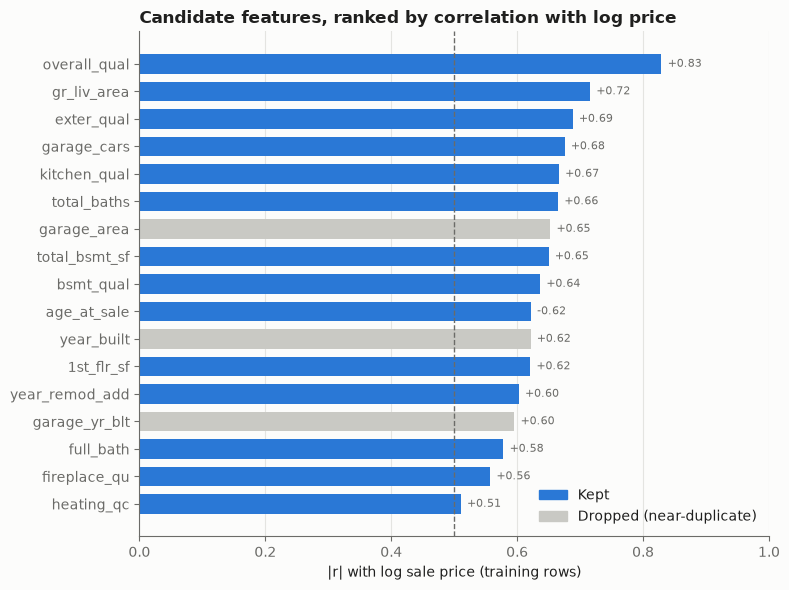

In [5]:
TEXT_COLOR, MUTED, GRID, SURFACE = "#1f1f1e", "#6b6b68", "#e4e4e1", "#fcfcfb"
BLUE, NEUTRAL = "#2a78d6", "#c9c9c4"
plt.rcParams.update({
    "axes.edgecolor": MUTED, "axes.labelcolor": TEXT_COLOR, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": TEXT_COLOR, "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.titlesize": 12, "axes.titleweight": "bold",
})


def plot_feature_ranking(ranking: pd.Series, candidates: list[str], kept: list[str]) -> None:
    """Bar chart of each candidate's correlation with log price, kept vs. dropped.

    Args:
        ranking: Every feature's r with log price.
        candidates: The features at or above the correlation floor.
        kept: The candidates left after dropping near-duplicates.
    """
    values = ranking[candidates][::-1]
    figure, axes = plt.subplots(figsize=(8, 6))
    axes.barh(values.index, values.abs(), height=0.7,
              color=[BLUE if feature in kept else NEUTRAL for feature in values.index])
    for row, r in enumerate(values):
        axes.text(abs(r) + 0.01, row, f"{r:+.2f}", va="center", fontsize=8, color=MUTED)
    axes.axvline(CORRELATION_FLOOR, color=MUTED, linewidth=1, linestyle="--")
    axes.set(xlim=(0, 1), xlabel="|r| with log sale price (training rows)")
    axes.set_title("Candidate features, ranked by correlation with log price", loc="left")
    axes.legend(handles=[Patch(color=BLUE, label="Kept"),
                         Patch(color=NEUTRAL, label="Dropped (near-duplicate)")],
                loc="lower right", frameon=False)
    axes.grid(axis="y", visible=False)
    figure.tight_layout()
    figure.savefig("q1_feature_ranking.png", dpi=150)
    plt.show()


plot_feature_ranking(RANKING, CANDIDATES, KEPT)

In [6]:
def build_model(estimator: BaseEstimator, numeric: list[str], nominal: list[str]) -> Pipeline:
    """Chain the preparation and the model, so every step learns from training rows only.

    Numbers: fill the rare gap with the median, then standardize. Text: one-hot encode, first
    category dropped.

    Args:
        estimator: LinearRegression or LogisticRegression.
        numeric: The numeric feature columns.
        nominal: The text feature columns.

    Returns:
        An unfitted pipeline.
    """
    parts = [("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
              numeric)]
    if nominal:
        parts.append(("categories", OneHotEncoder(drop="first", handle_unknown="ignore"),
                      nominal))
    return make_pipeline(ColumnTransformer(parts), estimator)


def compare_feature_sets(train: pd.DataFrame,
                         feature_sets: dict[str, tuple[list[str], list[str]]]) -> pd.DataFrame:
    """Cross-validate a linear model on log price for each feature set.

    Args:
        train: The training rows.
        feature_sets: Each set's name, mapped to its (numeric, nominal) features.

    Returns:
        One row per set: its size and its cross-validated R-squared and typical miss.
    """
    rows = []
    for name, (numeric, nominal) in feature_sets.items():
        scores = cross_validate(build_model(LinearRegression(), numeric, nominal),
                                train[numeric + nominal], train[LOG_PRICE], cv=CV_FOLDS,
                                scoring=("neg_root_mean_squared_error", "r2"))
        rmse = -scores["test_neg_root_mean_squared_error"].mean()
        rows.append({"feature set": name, "features": len(numeric) + len(nominal),
                     "CV R-squared": round(scores["test_r2"].mean(), 3),
                     "typical miss": f"{np.exp(rmse) - 1:.0%}"})
    return pd.DataFrame(rows).set_index("feature set")


print(compare_feature_sets(TRAIN, {
    "Top 5 by correlation": (CANDIDATES[:5], []),
    f"{len(KEPT)} kept + neighborhood (chosen)": (KEPT, NOMINAL_FEATURES),
    f"All {len(RANKING)} numeric columns": (list(RANKING.index), []),
}).to_string())

FEATURES = KEPT + NOMINAL_FEATURES

                                 features  CV R-squared typical miss
feature set                                                         
Top 5 by correlation                    5         0.810          20%
14 kept + neighborhood (chosen)        15         0.884          15%
All 47 numeric columns                 47         0.902          14%


**Why I chose these features:** In trying to predict sale price, I assume location would have been important, so I grabbed location and then began to look at the 47 numeric columns. After looking at each correlation with price and removing the near-duplicates, I settled on these 14 + neighborhood. Cross validation showed these 15 miss by about 15% on average, 5% better than top 5 alone and only 1 point worse than using all 47.

## Question 2: Linear regression

In [7]:
def regression_scores(actual_log: pd.Series, predicted_log: np.ndarray) -> dict[str, float]:
    """Score log-price predictions: R-squared on the log scale, errors in dollars.

    Args:
        actual_log: The true log prices.
        predicted_log: The predicted log prices.

    Returns:
        R-squared, RMSE in dollars and mean absolute error in dollars.
    """
    actual, predicted = np.exp(actual_log), np.exp(predicted_log)
    return {"R-squared": round(r2_score(actual_log, predicted_log), 3),
            "RMSE ($)": round(root_mean_squared_error(actual, predicted)),
            "mean absolute error ($)": round(mean_absolute_error(actual, predicted))}


LINEAR_MODEL = build_model(LinearRegression(), KEPT, NOMINAL_FEATURES)
LINEAR_MODEL.fit(TRAIN[FEATURES], TRAIN[LOG_PRICE])
print(pd.DataFrame({
    "training": regression_scores(TRAIN[LOG_PRICE], LINEAR_MODEL.predict(TRAIN[FEATURES])),
    "test": regression_scores(TEST[LOG_PRICE], LINEAR_MODEL.predict(TEST[FEATURES])),
    "baseline: predict the average (test)": regression_scores(
        TEST[LOG_PRICE], np.full(len(TEST), TRAIN[LOG_PRICE].mean())),
}).T.to_string())

                                      R-squared  RMSE ($)  mean absolute error ($)
training                                  0.890   22819.0                  16084.0
test                                      0.881   23749.0                  16876.0
baseline: predict the average (test)     -0.001   78512.0                  53584.0


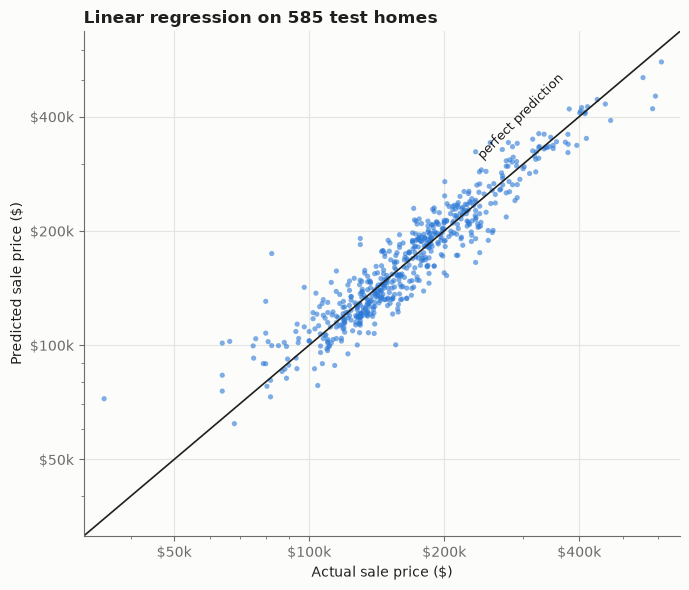

In [8]:
def plot_predicted_vs_actual(model: Pipeline, test: pd.DataFrame) -> None:
    """Scatter each test home's predicted price against its actual price, on log axes.

    Args:
        model: The fitted linear pipeline.
        test: The test rows.
    """
    actual, predicted = test[PRICE], np.exp(model.predict(test[FEATURES]))
    figure, axes = plt.subplots(figsize=(7, 6))
    axes.scatter(actual, predicted, s=14, alpha=0.6, color=BLUE, edgecolors="none")
    limits = [min(actual.min(), predicted.min()) * 0.9, max(actual.max(), predicted.max()) * 1.1]
    axes.plot(limits, limits, color=TEXT_COLOR, linewidth=1.2)
    axes.text(limits[1] * 0.55, limits[1] * 0.75, "perfect prediction", fontsize=9,
              ha="right", rotation=45, rotation_mode="anchor")
    ticks = [50_000, 100_000, 200_000, 400_000]
    axes.set(xscale="log", yscale="log", xlim=limits, ylim=limits, xticks=ticks, yticks=ticks,
             xlabel="Actual sale price ($)", ylabel="Predicted sale price ($)")
    for axis in (axes.xaxis, axes.yaxis):
        axis.set_major_formatter(FuncFormatter(lambda value, _: f"${value / 1000:,.0f}k"))
        axis.set_minor_formatter(NullFormatter())
    axes.set_title(f"Linear regression on {len(test)} test homes", loc="left")
    figure.tight_layout()
    figure.savefig("q2_predicted_vs_actual.png", dpi=150)
    plt.show()


plot_predicted_vs_actual(LINEAR_MODEL, TEST)

**Evaluation:** From the 80/20 train/test split from feature selection in Q1, I trained on 80% of the data and predicted with the other 20%. This graph compares the predictions with what the homes actually sold for. Guessing just by the average $54k so the model is 3x better at ~$17k average miss. This model does well because price is driven by quality, size, age and location, and the features covers each of those. I would be interested in looking at the interaction of quality and size more closely.

## Question 3: Logistic regression

In [9]:
CUTOFF = TRAIN[PRICE].median()             # the training median, so test rows don't set it
Y_TRAIN, Y_TEST = (TRAIN[PRICE] > CUTOFF).astype(int), (TEST[PRICE] > CUTOFF).astype(int)
print(f"Above ${CUTOFF:,.0f}: {Y_TRAIN.mean():.1%} of training homes, {Y_TEST.mean():.1%} of test")


def classification_scores(actual: pd.Series, predicted: np.ndarray) -> dict[str, float]:
    """Score yes/no predictions, where 1 means above the cutoff.

    Args:
        actual: The true labels.
        predicted: The predicted labels.

    Returns:
        Accuracy, precision, recall and F1.
    """
    return {"accuracy": round(accuracy_score(actual, predicted), 3),
            "precision": round(precision_score(actual, predicted, zero_division=0), 3),
            "recall": round(recall_score(actual, predicted, zero_division=0), 3),
            "F1": round(f1_score(actual, predicted, zero_division=0), 3)}


LOGISTIC_MODEL = build_model(LogisticRegression(max_iter=1000), KEPT, NOMINAL_FEATURES)
LOGISTIC_MODEL.fit(TRAIN[FEATURES], Y_TRAIN)
print(pd.DataFrame({
    "training": classification_scores(Y_TRAIN, LOGISTIC_MODEL.predict(TRAIN[FEATURES])),
    "test": classification_scores(Y_TEST, LOGISTIC_MODEL.predict(TEST[FEATURES])),
    "baseline: always guess the larger class (test)": classification_scores(
        Y_TEST, np.full(len(TEST), Y_TRAIN.mode().iloc[0])),
}).T.to_string())

Above $160,000: 49.5% of training homes, 51.3% of test
                                                accuracy  precision  recall     F1
training                                           0.923      0.920   0.925  0.923
test                                               0.918      0.932   0.907  0.919
baseline: always guess the larger class (test)     0.487      0.000   0.000  0.000


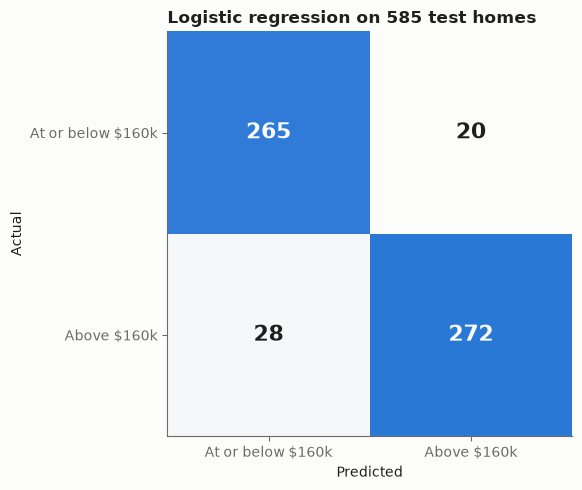

In [10]:
def plot_confusion_matrix(model: Pipeline, test: pd.DataFrame) -> None:
    """Draw the 2 x 2 confusion matrix for the test homes, with the count in each cell.

    Args:
        model: The fitted logistic pipeline.
        test: The test rows.
    """
    matrix = confusion_matrix(Y_TEST, model.predict(test[FEATURES]))
    labels = [f"At or below ${CUTOFF / 1000:,.0f}k", f"Above ${CUTOFF / 1000:,.0f}k"]
    figure, axes = plt.subplots(figsize=(6, 5))
    axes.imshow(matrix, cmap=LinearSegmentedColormap.from_list("blues", [SURFACE, BLUE]))
    for (row, column), count in np.ndenumerate(matrix):
        axes.text(column, row, f"{count}", ha="center", va="center", fontsize=16,
                  fontweight="bold", color=SURFACE if count > matrix.max() / 2 else TEXT_COLOR)
    axes.set(xticks=[0, 1], yticks=[0, 1], xticklabels=labels, yticklabels=labels,
             xlabel="Predicted", ylabel="Actual")
    axes.grid(False)
    axes.set_title(f"Logistic regression on {len(test)} test homes", loc="left")
    figure.tight_layout()
    figure.savefig("q3_confusion_matrix.png", dpi=150)
    plt.show()


plot_confusion_matrix(LOGISTIC_MODEL, TEST)

**Preparing the same dataset for both:** The model for both linear and logistic regression can share the same preprocessing, feature selection, and same pipeline from build_model. What changes is the target, where linear regression is looking at predicting the sale price, logistic regression is looking at is the predicted house going to sell above or below the $160k median. The metrics change from R_squared, RMSE and MAE for linear regression to accuracy, precision, recall and F1 for logistic.

**Evaluation:** This logistic regression model predicts correctly 91.8% of the time against 48.7% baseline. Precision of 0.93 means when it predicts above $160k it's usually right, and recall of 0.91 means it catches most of the homes that really are above. This would indicate that the features that predict price well, also separate cheap from expensive houses pretty easily, but there errors live when homes are priced around the $160k mark.

*AI use: see `AI_COLLABORATION.md`.*